# code_149 · Benchmark provenance, independent sites and context contamination

**Book:** section 28.6. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Task inputs and helpers are internal. Ordinary execution is offline and CPU-only after the explicit one-time public checkpoint acquisition in the asset guide; local weights are hash-verified, and missing assets fail with instructions. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_149).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3549;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3549


<a id="benchmark-evidence-contract"></a>
 ## A public benchmark score is not an independent-site guarantee
 Use the pinned TabICLv2 classifier and offline asset checks. Three small public tables bundled with scikit-learn (Iris, Wine and Wisconsin diagnostic breast-cancer) use stratified60/20/20row splits. They are method benchmarks, not clinical or field recommendations; their upstream role in checkpoint/model development is not independently verified here. Twelve further tables are newly generated: sixty buildings×8records each, split40source/10development/10final buildings. Six keep the source mechanism; six deliberately reverse one final-site coefficient and shift one input. Each family gets two development-selected candidates: TabICL ensemble1/4 or native histogram leaves7/15,100rounds/rate0.05. Source/final exact-feature overlap is audited. A separate invalid fixture admits20final labels into context; its score is retained only as contaminated evidence.


,table,cohort,family,selected_candidate,source_records,development_records,final_records,classes,final_log_loss,source_prior_log_loss
0,Iris,Bundled public row splits,TabICLv2,4,90,30,30,3,0.015754,1.098612
1,Iris,Bundled public row splits,Histogram booster,7,90,30,30,3,0.025043,1.098612
2,Wine,Bundled public row splits,TabICLv2,4,106,36,36,3,0.008615,1.089398
3,Wine,Bundled public row splits,Histogram booster,7,106,36,36,3,0.089369,1.089398
4,Wisconsin diagnostic,Bundled public row splits,TabICLv2,1,341,114,114,2,0.134307,0.658151
5,Wisconsin diagnostic,Bundled public row splits,Histogram booster,7,341,114,114,2,0.169913,0.658151
6,Generated table 01,New source-mechanism buildings,TabICLv2,1,320,80,80,2,0.493683,0.667496
7,Generated table 01,New source-mechanism buildings,Histogram booster,7,320,80,80,2,0.515733,0.667496
8,Generated table 02,New source-mechanism buildings,TabICLv2,4,320,80,80,2,0.620272,0.670635
9,Generated table 02,New source-mechanism buildings,Histogram booster,7,320,80,80,2,0.618069,0.670635


,table,cohort,exact_final_feature_rows_in_source,provenance
0,Iris,Bundled public row splits,0,Public sklearn-bundled reference; upstream mod...
1,Wine,Bundled public row splits,0,Public sklearn-bundled reference; upstream mod...
2,Wisconsin diagnostic,Bundled public row splits,0,Public sklearn-bundled reference; upstream mod...
3,Generated table 01,New source-mechanism buildings,0,Fresh generated task instances after immutable...
4,Generated table 02,New source-mechanism buildings,0,Fresh generated task instances after immutable...
5,Generated table 03,New source-mechanism buildings,0,Fresh generated task instances after immutable...
6,Generated table 04,New source-mechanism buildings,0,Fresh generated task instances after immutable...
7,Generated table 05,New source-mechanism buildings,0,Fresh generated task instances after immutable...
8,Generated table 06,New source-mechanism buildings,0,Fresh generated task instances after immutable...
9,Generated table 07,Changed final mechanism,0,Fresh generated task instances after immutable...


Paired table uncertainty: [{'cohort': 'New source-mechanism buildings', 'independent_generated_tables': 6, 'mean_paired_log_loss_TabICL_minus_tree': -0.021300882087708622, 'table_bootstrap95_interval': [-0.04143941213745369, -0.003693155872252052], 'resamples': 2000}, {'cohort': 'Changed final mechanism', 'independent_generated_tables': 6, 'mean_paired_log_loss_TabICL_minus_tree': 0.03765390875169097, 'table_bootstrap95_interval': [-0.03140965643032823, 0.1389733569128729], 'resamples': 2000}] Invalid context fixture: {'valid_evidence': False, 'final_labels_wrongly_admitted_to_context': 20, 'detected_final_feature_rows_in_context': 20, 'valid_final_log_loss': 0.493683397769928, 'contaminated_final_log_loss': 0.48244303464889526, 'valid_leaked_subset_log_loss': 0.6228333711624146, 'contaminated_leaked_subset_log_loss': 0.5865758061408997}


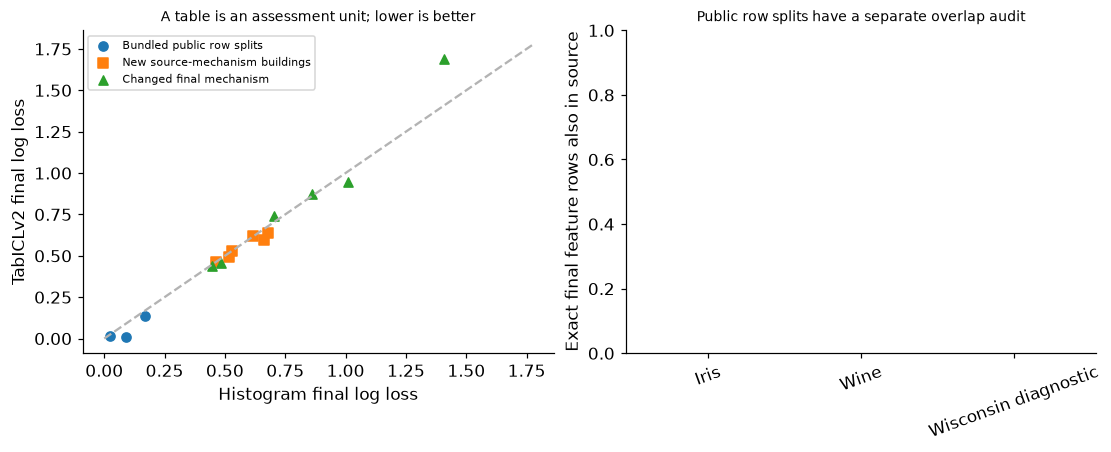

In [2]:
import os,hashlib,importlib.metadata as metadata
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabicl import TabICLClassifier
from sklearn.datasets import load_iris,load_wine,load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
VERSIONS['tabicl']=metadata.version('tabicl');ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (p/'examples.json').is_file());revision='4dcd344ece2c00be9e831fdd35bed57b5ad83e19';checkpoint=ROOT/'build/model-cache/models--jingang--TabICL/snapshots'/revision/'tabicl-classifier-v2-20260212.ckpt';digest='bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0';assert checkpoint.is_file(),'Run python scripts/acquire_chapter28_models.py';assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==digest
tables=[]
for name,loader in [('Iris',load_iris),('Wine',load_wine),('Wisconsin diagnostic',load_breast_cancer)]:
    data=loader();x=np.asarray(data.data,dtype=np.float64);y=np.asarray(data.target);ids=np.arange(len(y));source,rest=train_test_split(ids,test_size=.4,stratify=y,random_state=SEED);dev,final=train_test_split(rest,test_size=.5,stratify=y[rest],random_state=SEED+1);tables.append({'name':name,'cohort':'Bundled public row splits','x':x,'y':y,'source':source,'development':dev,'final':final,'provenance':'Public sklearn-bundled reference; upstream model-development overlap not independently verified'})
for j in range(12):
    building=np.repeat(np.arange(60),8);x=rng.normal(size=(480,5));weights=rng.normal(size=5);weights/=np.linalg.norm(weights);effect=rng.normal(0,.4,60)[building];changed=j>=6;x[building>=50,0]+=1.2*changed;score=-.5+1.7*x@weights+.5*np.sin(x[:,1]*x[:,2])+effect
    if changed:score[building>=50]-=3.4*x[building>=50,0]*weights[0]
    y=rng.binomial(1,1/(1+np.exp(-score)));source=np.flatnonzero(building<40);dev=np.flatnonzero((building>=40)&(building<50));final=np.flatnonzero(building>=50);tables.append({'name':f'Generated table {j+1:02d}','cohort':'Changed final mechanism' if changed else 'New source-mechanism buildings','x':x,'y':y,'source':source,'development':dev,'final':final,'provenance':'Fresh generated task instances after immutable checkpoint; not private-site evidence'})
def fingerprints(x):return [hashlib.sha256(np.ascontiguousarray(row,dtype='<f8').tobytes()).hexdigest() for row in x]
def native(ensemble):return TabICLClassifier(n_estimators=ensemble,model_path=checkpoint,allow_auto_download=False,device='cpu',use_amp=False,use_fa3=False,n_jobs=1,random_state=SEED)
rows=[];selection=[];audits=[];saved=None
for table in tables:
    x,y=table['x'],table['y'];s,d,f=table['source'],table['development'],table['final'];classes=np.unique(y[s]);assert np.array_equal(classes,np.arange(len(classes)));overlap=int(sum(value in set(fingerprints(x[s])) for value in fingerprints(x[f])));audits.append({'table':table['name'],'cohort':table['cohort'],'exact_final_feature_rows_in_source':overlap,'provenance':table['provenance']});best={}
    for family in ['TabICLv2','Histogram booster']:
        for candidate in ([1,4] if family=='TabICLv2' else [7,15]):
            model=native(candidate) if family=='TabICLv2' else HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=candidate,min_samples_leaf=10,learning_rate=.05,l2_regularization=1,early_stopping=False,random_state=SEED);model.fit(x[s],y[s]);p=model.predict_proba(x[d]);score=float(log_loss(y[d],p,labels=classes));selection.append({'table':table['name'],'family':family,'candidate':candidate,'development_log_loss':score})
            if family not in best or score<best[family][0]:best[family]=(score,candidate,model)
        _,candidate,model=best[family];p=model.predict_proba(x[f]);np.testing.assert_allclose(p.sum(1),np.ones(len(f)),atol=2e-6);prior=(np.bincount(y[s],minlength=len(classes))+.5)/(len(s)+.5*len(classes));constant=np.tile(prior,(len(f),1));rows.append({'table':table['name'],'cohort':table['cohort'],'family':family,'selected_candidate':candidate,'source_records':len(s),'development_records':len(d),'final_records':len(f),'classes':len(classes),'final_log_loss':float(log_loss(y[f],p,labels=classes)),'source_prior_log_loss':float(log_loss(y[f],constant,labels=classes))})
    if table['name']=='Generated table 01':saved=(table,best['TabICLv2'][1],best['TabICLv2'][2])
paired=[]
for cohort in ['New source-mechanism buildings','Changed final mechanism']:
    names=[t['name'] for t in tables if t['cohort']==cohort];differences=np.array([next(r['final_log_loss'] for r in rows if r['table']==name and r['family']=='TabICLv2')-next(r['final_log_loss'] for r in rows if r['table']==name and r['family']=='Histogram booster') for name in names]);bootstrap=np.mean(differences[rng.integers(0,len(differences),(2000,len(differences)))],axis=1);paired.append({'cohort':cohort,'independent_generated_tables':len(names),'mean_paired_log_loss_TabICL_minus_tree':float(differences.mean()),'table_bootstrap95_interval':np.quantile(bootstrap,[.025,.975]).tolist(),'resamples':2000})
table,candidate,valid_model=saved;x,y=table['x'],table['y'];s,f=table['source'],table['final'];leaked=f[:20];contaminated=native(candidate).fit(np.vstack([x[s],x[leaked]]),np.r_[y[s],y[leaked]]);p_bad=contaminated.predict_proba(x[f]);p_valid=valid_model.predict_proba(x[f]);source_fingerprints=set(fingerprints(np.vstack([x[s],x[leaked]])));overlap=int(sum(value in source_fingerprints for value in fingerprints(x[f])));assert overlap==20;leakage={'valid_evidence':False,'final_labels_wrongly_admitted_to_context':20,'detected_final_feature_rows_in_context':overlap,'valid_final_log_loss':float(log_loss(y[f],p_valid,labels=[0,1])),'contaminated_final_log_loss':float(log_loss(y[f],p_bad,labels=[0,1])),'valid_leaked_subset_log_loss':float(log_loss(y[leaked],p_valid[:20],labels=[0,1])),'contaminated_leaked_subset_log_loss':float(log_loss(y[leaked],p_bad[:20],labels=[0,1]))}
assert all(r['exact_final_feature_rows_in_source']==0 for r in audits if r['cohort']!='Bundled public row splits')
RESULTS.update(public_tables=3,generated_tables=12,candidates_per_family_per_table=2,public_split='stratified random rows60/20/20',generated_split='whole buildings40/10/10,8records each',checkpoint_sha256=digest,comparisons=rows,candidate_selection=selection,overlap_and_provenance=audits,paired_generated_table_uncertainty=paired,deliberately_contaminated_fixture=leakage);display(pd.DataFrame(rows));display(pd.DataFrame(audits));print('Paired table uncertainty:',paired,'Invalid context fixture:',leakage)
fig,axes=plt.subplots(1,2,figsize=(10,4));styles={'Bundled public row splits':'o','New source-mechanism buildings':'s','Changed final mechanism':'^'}
for cohort,marker in styles.items():
    names=[t['name'] for t in tables if t['cohort']==cohort];tx=[next(r['final_log_loss'] for r in rows if r['table']==name and r['family']=='Histogram booster') for name in names];ty=[next(r['final_log_loss'] for r in rows if r['table']==name and r['family']=='TabICLv2') for name in names];axes[0].scatter(tx,ty,marker=marker,label=cohort)
upper=max(r['final_log_loss'] for r in rows)*1.05;axes[0].plot([0,upper],[0,upper],'--',color='.7');axes[0].set(xlabel='Histogram final log loss',ylabel='TabICLv2 final log loss',title='A table is an assessment unit; lower is better');axes[0].legend(fontsize=7);public=[r for r in audits if r['cohort']=='Bundled public row splits'];axes[1].bar([r['table'] for r in public],[r['exact_final_feature_rows_in_source'] for r in public],color='.5');axes[1].set(ylabel='Exact final feature rows also in source',title='Public row splits have a separate overlap audit');axes[1].tick_params(axis='x',labelrotation=20);axes[1].set_ylim(0,max(1,max(r['exact_final_feature_rows_in_source'] for r in public)+1));plt.show()


<a id="bounded-benchmark-conclusions"></a>
 ## Match the evidence unit, provenance and recommendation
 All public and generated tables retain their own task counts, class counts, source priors and selected candidates. Public random-row scores do not certify unseen-building transfer or an absence of upstream benchmark influence. Fresh generated task instances are not private unseen-site observations, and their controlled function shifts are not a survey of operational drift. Equal candidate counts do not equalize checkpoint pretraining, model size or actual compute. The two table-bootstrap intervals resample six independent generated tables within each declared cohort, not thousands of correlated prediction rows; they describe this small constructed task distribution. The separate contaminated context example deliberately admits final outcomes even though its neural weights remain frozen. An apparent score gain cannot make that information boundary valid. No recommendation claims universal performance, real private-site evidence or a verified census of the checkpoint's pretraining rows.


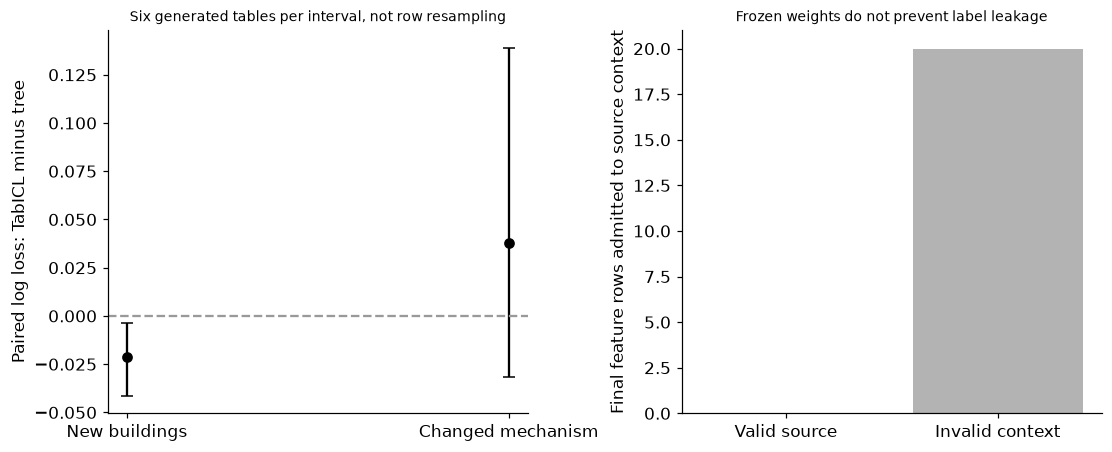

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));means=np.array([r['mean_paired_log_loss_TabICL_minus_tree'] for r in paired]);intervals=np.array([r['table_bootstrap95_interval'] for r in paired]);axes[0].errorbar([0,1],means,yerr=np.vstack([means-intervals[:,0],intervals[:,1]-means]),fmt='o',color='black',capsize=4);axes[0].axhline(0,color='.6',linestyle='--');axes[0].set(xticks=[0,1],xticklabels=['New buildings','Changed mechanism'],ylabel='Paired log loss: TabICL minus tree',title='Six generated tables per interval, not row resampling');axes[1].bar(['Valid source','Invalid context'],[0,leakage['detected_final_feature_rows_in_context']],color=['.3','.7']);axes[1].set(ylabel='Final feature rows admitted to source context',title='Frozen weights do not prevent label leakage');plt.show()
assert len(rows)==30 and len(selection)==60 and len(audits)==15


In [4]:
summary={'example_id':'code_149','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned native model and tree comparisons across public and generated tables', 'separate random-row versus whole-entity assessment', 'equal explicit candidate counts without lifetime-compute claims', 'table-level paired uncertainty with named task families', 'actual final-label context leakage fixture and overlap hashes'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned native model and tree comparisons across public and generated tables", "separate random-row versus whole-entity assessment", "equal explicit candidate counts without lifetime-compute claims", "table-level paired uncertainty with named task families", "actual final-label context leakage fixture and overlap hashes"], "elapsed_seconds": 14.285, "example_id": "code_149", "hardware": "Darwin arm64 CPU", "results": {"candidate_selection": [{"candidate": 1, "development_log_loss": 0.06669963151216507, "family": "TabICLv2", "table": "Iris"}, {"candidate": 4, "development_log_loss": 0.0639984980225563, "family": "TabICLv2", "table": "Iris"}, {"candidate": 7, "development_log_loss": 0.09813316043672507, "family": "Histogram booster", "table": "Iris"}, {"candidate": 15, "development_log_loss": 0.09813316043672507, "family": "Histogram booster", "table": "Iris"}, {"candidate": 1, "development_log_loss": 0.01881445199251175, "family":